In [ ]:
#!pip install albumentations opencv-python matplotlib
#!pip install ultralytics
#!pip install ultralytics opencv-python torch torchvision matplotlib numpy pillow
!pip install tensorflow opencv-python matplotlib numpy pillow scikit-learn

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Weather Augmentation Module
import albumentations as A

def get_weather_transform():
    transform = A.Compose([
        A.RandomRain(p=0.3),
        A.RandomFog(p=0.3),
        A.RandomSnow(p=0.2),
        A.MotionBlur(p=0.3),
        A.RandomBrightnessContrast(p=0.4),
        A.GaussNoise(p=0.2)
    ])
    return transform

In [ ]:
#Image Enhancement Module
import cv2
import numpy as np

def clahe_enhancement(image):
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    cl = clahe.apply(l)

    merged = cv2.merge((cl, a, b))
    enhanced = cv2.cvtColor(merged, cv2.COLOR_LAB2RGB)

    return enhanced

def sharpen_image(image):
    kernel = np.array([[0,-1,0],
                       [-1,5,-1],
                       [0,-1,0]])
    return cv2.filter2D(image, -1, kernel)

In [ ]:
#Custom Dataset Loader (DFR Dataset)
import os
import cv2
import torch
from torch.utils.data import Dataset
from torchvision import transforms
#from weather_aug import get_weather_transform
#from enhancement import clahe_enhancement, sharpen_image

class DFRDataset(Dataset):
    def __init__(self, root_dir):
        self.root_dir = root_dir
        self.classes = os.listdir(root_dir)
        self.image_paths = []
        self.labels = []

        for label in self.classes:
            class_path = os.path.join(root_dir, label)
            for img in os.listdir(class_path):
                self.image_paths.append(os.path.join(class_path, img))
                self.labels.append(int(label))

        self.weather = get_weather_transform()
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Resize((224,224))
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = cv2.imread(self.image_paths[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Weather simulation
        img = self.weather(image=img)['image']

        # Enhancement
        img = clahe_enhancement(img)
        img = sharpen_image(img)

        img = self.transform(img)

        label = torch.tensor(self.labels[idx])

        return img, label


In [ ]:
#DFR-TSD Model (ResNet50 + Attention)
import torch
import torch.nn as nn
import torchvision.models as models

class DFR_TSD(nn.Module):
    def __init__(self, num_classes):
        super(DFR_TSD, self).__init__()

        self.backbone = models.resnet50(pretrained=True)
        in_features = self.backbone.fc.in_features

        # Remove last FC
        self.backbone.fc = nn.Identity()

        # Classifier Head
        self.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.backbone(x)
        x = self.classifier(x)
        return x

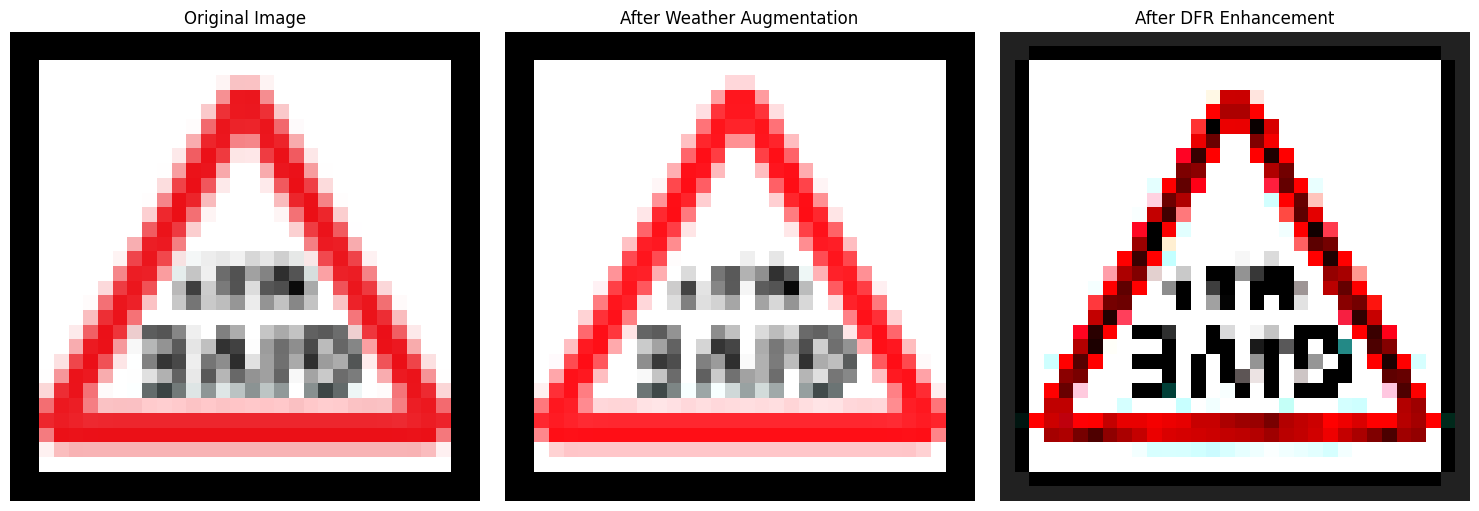

In [ ]:
import cv2
import matplotlib.pyplot as plt
#from weather_aug import get_weather_transform
#from enhancement import clahe_enhancement, sharpen_image

# Load one sample image
image_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/Images/0/0_original_43.png_592b345c-34ee-4cc5-b2f4-774db9375ab8.png"  # change to your image path
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Apply Weather Augmentation
weather = get_weather_transform()
augmented = weather(image=image)['image']

# Apply Enhancement Block (DFR Module)
enhanced = clahe_enhancement(augmented)
enhanced = sharpen_image(enhanced)

# Plot Results
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(augmented)
plt.title("After Weather Augmentation")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(enhanced)
plt.title("After DFR Enhancement")
plt.axis("off")

plt.tight_layout()
plt.show()

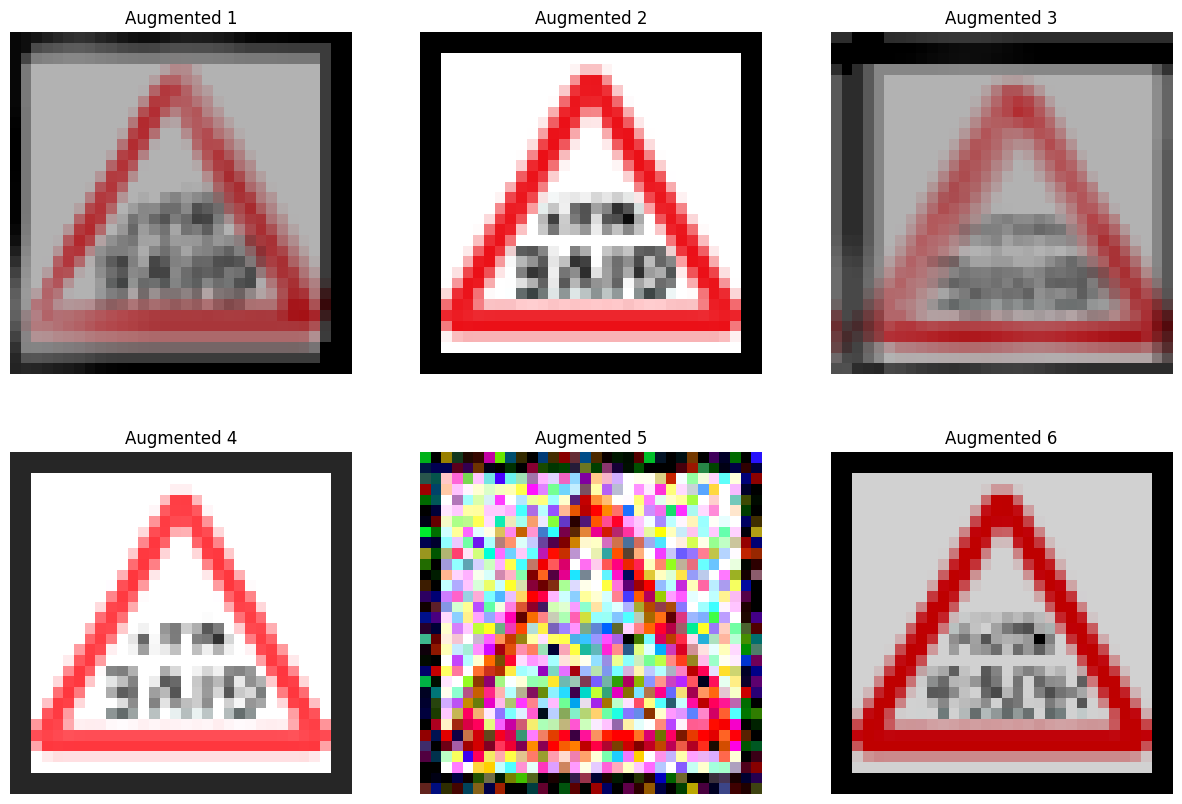

In [ ]:
plt.figure(figsize=(15,10))

for i in range(6):
    augmented = weather(image=image)['image']

    plt.subplot(2,3,i+1)
    plt.imshow(augmented)
    plt.title(f"Augmented {i+1}")
    plt.axis("off")

plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
#from dataset import DFRDataset
#from model import DFR_TSD
from tqdm import tqdm
import matplotlib.pyplot as plt
import os

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Load Dataset
dataset = DFRDataset("/content/drive/MyDrive/SEM-8 MAJOR PROJECT/Images")

# Split into Train & Validation (80-20)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

num_classes = 59#len(dataset.classes)

model = DFR_TSD(num_classes).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.0003)

EPOCHS = 10

# Store history
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader):
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_accuracy = 100 * correct / total

    # Validation
    model.eval()
    val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_accuracy = 100 * correct / total

    train_losses.append(train_loss / len(train_loader))
    val_losses.append(val_loss / len(val_loader))
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss: {train_losses[-1]:.4f}, Train Acc: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_losses[-1]:.4f}, Val Acc: {val_accuracy:.2f}%")

save_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/models"
os.makedirs(save_path, exist_ok=True)  # Create folder if it doesn't exist

torch.save(model.state_dict(), os.path.join(save_path, "DFR_TSD.pth"))

100%|██████████| 350/350 [1:16:06<00:00, 13.05s/it]



Epoch [1/10]
Train Loss: 2.2508, Train Acc: 38.70%
Val Loss: 1.1749, Val Acc: 62.90%


100%|██████████| 350/350 [03:27<00:00,  1.69it/s]



Epoch [2/10]
Train Loss: 1.1657, Train Acc: 65.00%
Val Loss: 0.8789, Val Acc: 72.74%


100%|██████████| 350/350 [03:27<00:00,  1.69it/s]



Epoch [3/10]
Train Loss: 0.9337, Train Acc: 71.66%
Val Loss: 0.8095, Val Acc: 73.63%


... (10 outputs left out)

100%|██████████| 350/350 [03:25<00:00,  1.70it/s]



Epoch [9/10]
Train Loss: 0.6179, Train Acc: 79.95%
Val Loss: 0.5727, Val Acc: 80.11%


100%|██████████| 350/350 [03:26<00:00,  1.69it/s]



Epoch [10/10]
Train Loss: 0.6196, Train Acc: 79.81%
Val Loss: 0.5271, Val Acc: 81.61%


In [ ]:
import torch
import cv2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = DFR_TSD(num_classes=59)
model.load_state_dict(torch.load("/content/drive/MyDrive/SEM-8 MAJOR PROJECT/models/DFR_TSD.pth"))
model = model.to(DEVICE)   # 🔥 ADD THIS LINE
model.eval()

image = cv2.imread("/content/drive/MyDrive/SEM-8 MAJOR PROJECT/Images/0/0_original_43_original_43.png_02661bd5-3d5b-4478-a571-ad74f652ca39.png_239f85c7-fa52-4377-b712-d6be292dcc0c.png")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image = cv2.resize(image, (224,224))
image = torch.tensor(image).permute(2,0,1).float()/255
image = image.unsqueeze(0).to(DEVICE)

with torch.no_grad():   # 🔥 recommended for inference
    output = model(image)

prediction = torch.argmax(output, dim=1)
print("Predicted Class:", prediction.item())

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 70.1MB/s]


Predicted Class: 0


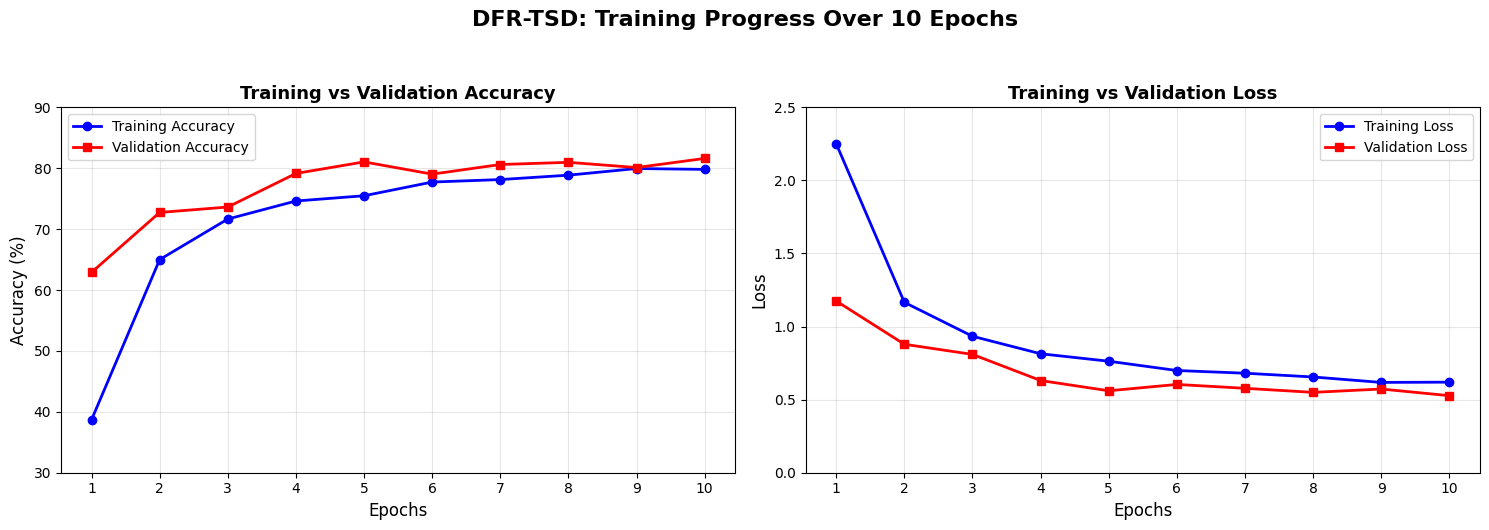

In [ ]:
import matplotlib.pyplot as plt

# Your data
epochs = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
train_acc = [38.70, 65.00, 71.66, 74.62, 75.48, 77.73, 78.14, 78.86, 79.95, 79.81]
val_acc = [62.90, 72.74, 73.63, 79.14, 81.04, 79.03, 80.61, 80.97, 80.11, 81.61]
train_loss = [2.2508, 1.1657, 0.9337, 0.8140, 0.7629, 0.6993, 0.6809, 0.6551, 0.6179, 0.6196]
val_loss = [1.1749, 0.8789, 0.8095, 0.6308, 0.5607, 0.6040, 0.5776, 0.5498, 0.5727, 0.5271]

# Create figure with 2 subplots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Accuracy
ax1.plot(epochs, train_acc, 'b-', marker='o', linewidth=2, markersize=6, label='Training Accuracy')
ax1.plot(epochs, val_acc, 'r-', marker='s', linewidth=2, markersize=6, label='Validation Accuracy')
ax1.set_xlabel('Epochs', fontsize=12)
ax1.set_ylabel('Accuracy (%)', fontsize=12)
ax1.set_title('Training vs Validation Accuracy', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_xticks(epochs)
ax1.set_ylim(30, 90)  # Set y-axis limits for better comparison

# Plot 2: Loss
ax2.plot(epochs, train_loss, 'b-', marker='o', linewidth=2, markersize=6, label='Training Loss')
ax2.plot(epochs, val_loss, 'r-', marker='s', linewidth=2, markersize=6, label='Validation Loss')
ax2.set_xlabel('Epochs', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.set_title('Training vs Validation Loss', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_xticks(epochs)
ax2.set_ylim(0, 2.5)  # Set y-axis limits for better comparison

# Add a main title
fig.suptitle('DFR-TSD: Training Progress Over 10 Epochs', fontsize=16, fontweight='bold', y=1.05)

plt.tight_layout()
plt.show()